# 03 Model experiments
Reads `artifacts/metrics.json` written by `scripts/train.py`. Test period is a chronological hold-out; thresholds were chosen on validation only. **Synthetic data, so results are optimistic.**

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
from identitygraph.models.registry import load_json
rep = load_json('metrics.json')
print(rep['version'], rep['primary_model'], rep['data'])

0.1.0-202611130301 graph_gradient_boosting {'n_total': 20000, 'n_train': 12000, 'n_val': 4000, 'n_test': 4000, 'train_end': '2025-05-25 03:18:03.116360818', 'fraud_rate_test': 0.09425, 'synthetic': True}


In [2]:
rows = []
for name, r in rep['models'].items():
    for split in ('validation', 'test'):
        m = r[split]
        rows.append(dict(model=name, split=split, pr_auc=m['pr_auc'], roc_auc=m['roc_auc'], precision=m['precision'], recall=m['recall'], f1=m['f1'], recall_at_1pct_fpr=m['recall_at_1pct_fpr']))
tab = pd.DataFrame(rows)
tab[tab.split == 'test'].drop(columns='split').set_index('model').round(3)

,pr_auc,roc_auc,precision,recall,f1,recall_at_1pct_fpr
model,,,,,,
logistic_regression,0.755,0.897,0.759,0.692,0.724,0.509
random_forest,0.819,0.913,0.942,0.729,0.822,0.753
gradient_boosting,0.830,0.924,0.964,0.714,0.820,0.732
graph_gradient_boosting,0.845,0.923,0.912,0.767,0.833,0.772
xgboost,0.829,0.917,0.911,0.732,0.812,0.743
graph_xgboost,0.845,0.921,0.950,0.761,0.845,0.777
lightgbm,0.828,0.919,0.923,0.729,0.815,0.743
graph_lightgbm,0.844,0.920,0.934,0.756,0.836,0.775


split                     test  validation
model                                     
gradient_boosting        0.830       0.816
graph_gradient_boosting  0.845       0.826
graph_lightgbm           0.844       0.823
graph_xgboost            0.845       0.823
lightgbm                 0.828       0.809
logistic_regression      0.755       0.691
random_forest            0.819       0.818
xgboost                  0.829       0.813


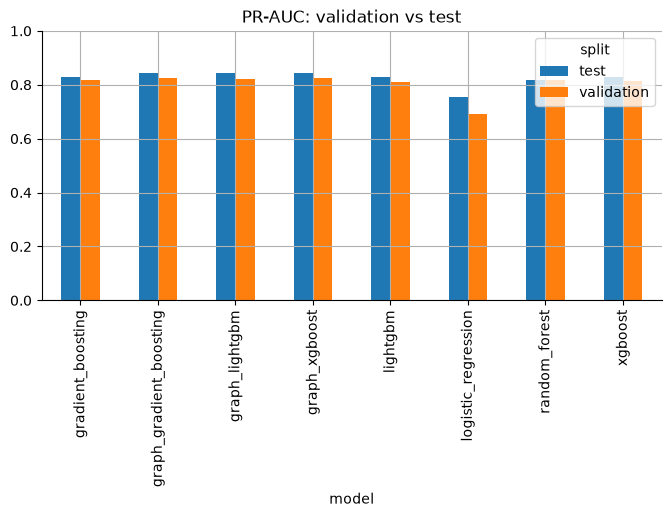

In [3]:
piv = tab.pivot(index='model', columns='split', values='pr_auc')
print(piv.round(3))
piv.plot.bar(title='PR-AUC: validation vs test'); plt.ylim(0, 1);

## Does the graph help?
Compare each graph-enhanced model with its same-family baseline.

In [4]:
pairs = [(a, 'graph_' + a) for a in ('gradient_boosting', 'xgboost', 'lightgbm') if 'graph_' + a in rep['models']]
out = pd.DataFrame({a: [rep['models'][a]['test']['pr_auc'], rep['models'][g]['test']['pr_auc']] for a, g in pairs}, index=['baseline', 'with graph features'])
out.loc['lift'] = out.loc['with graph features'] - out.loc['baseline']
out.round(3)

,gradient_boosting,xgboost,lightgbm
baseline,0.830,0.829,0.828
with graph features,0.845,0.845,0.844
lift,0.016,0.016,0.017


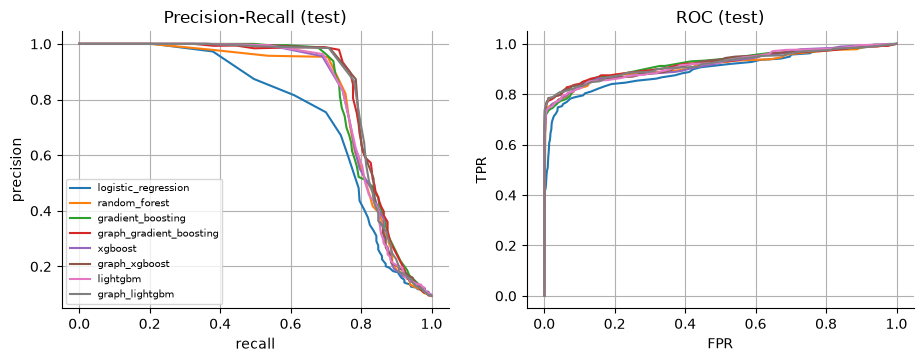

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for n, r in rep['models'].items():
    p = np.array(r['curves_test']['pr']); axs[0].plot(p[:, 0], p[:, 1], label=n)
    c = np.array(r['curves_test']['roc']); axs[1].plot(c[:, 0], c[:, 1], label=n)
axs[0].set(title='Precision-Recall (test)', xlabel='recall', ylabel='precision'); axs[1].set(title='ROC (test)', xlabel='FPR', ylabel='TPR'); axs[0].legend(fontsize=7);

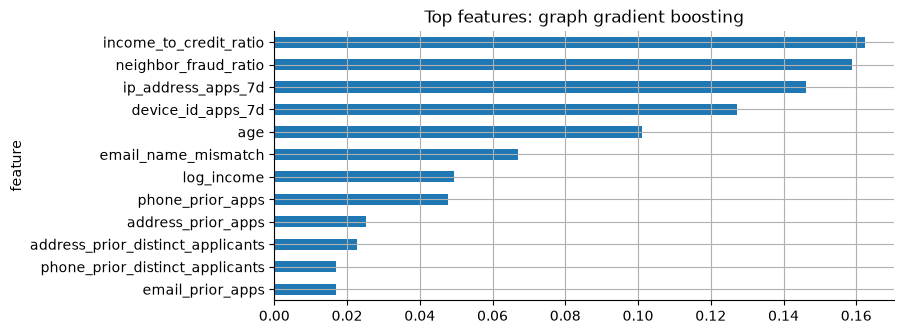

In [6]:
fi = pd.DataFrame(rep['models']['graph_gradient_boosting']['feature_importance']).set_index('feature')
fi.head(12).plot.barh(legend=False, title='Top features: graph gradient boosting').invert_yaxis();

In [7]:
cm = rep['models'][rep['primary_model']]['test']['confusion_matrix']; print(rep['primary_model'], cm)
print('thresholds (validation-selected):', rep['models'][rep['primary_model']]['thresholds'])

graph_gradient_boosting {'tn': 3595, 'fp': 28, 'fn': 88, 'tp': 289}
thresholds (validation-selected): {'medium': 0.02938060722661485, 'high': 0.16831498333222258, 'max_review_rate': 0.15, 'selected_on': 'validation'}


**Caveats:** single seed, no confidence intervals, uncalibrated scores, synthetic fraud patterns with explicit signals.